# Построение мультимодального baseline-пайплайна по результатам EDA

## Цель notebook
Цель этого notebook — собрать и проверить **инженерный baseline-контур** мультимодальной подготовки данных для последующего моделирования в `03_lightweight_multimodal_system.ipynb`. Здесь не решается задача максимизации финального качества; фокус сделан на воспроизводимой логике сборки датасета, контроле leakage и проверке того, что multi-rate связка log+KPI действительно работает в базовом режиме.

По выводам `01_eda.ipynb` отдельно учитываются ограничения KPI-модальности: неоднородное временное разрешение, низкое покрытие `kpi_available` на части эпизодов и риск shortcut-сигнала через один только факт доступности KPI.

## Аналитические вопросы
1. Какие наблюдения из EDA становятся обязательными правилами baseline-pipeline?
2. Как построить multi-rate схему: macro-контекст логов (5 минут) + micro-динамика (10s/30s)?
3. Как ввести две цели (`y_warning`, `y_risk`/`y_anomaly`) и сохранить anti-leakage split?
4. Как контролировать shortcut-эффект через `kpi_available` и оценивать срезы покрытия модальностей?
5. Работает ли собранный контур на уровне smoke-моделей (`log-only`, `kpi-only`, `fused`, `availability-only`)?


In [1]:
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)

ROOT = Path.cwd()
LOG_PATH = ROOT / "log_csv" / "drain_labeled.csv"
KPI_ROOT = ROOT / "kpi_csv"

BASELINE_FROM_MIN = 60
LEAD_FROM_MIN = 15
LEAD_TO_MIN = 1

WARNING_FROM_MIN = 15
WARNING_TO_MIN = 5
RISK_FROM_MIN = 5
RISK_TO_MIN = 1

MACRO_WINDOW = "5min"
MICRO_WINDOWS = ["10s", "30s"]
TOLERANCE_CANDIDATES = [5, 10, 15, 20]
DEFAULT_WINDOW = MACRO_WINDOW

TIME_COLS = ["timestamp", "Timestamp", "time", "Time"]
LABEL_COLS = ["label", "Label"]


## 1. Переход от EDA к правилам pipeline

В начале необходимо формализовать переход от описательного этапа к этапу подготовки данных. Поэтому каждый существенный вывод EDA далее связывается с конкретным правилом pipeline и с тем методологическим риском, который это правило снимает.

| Наблюдение из EDA | Правило в pipeline | Какой риск снимается |
|---|---|---|
| Логи содержат дубликаты и локальные инверсии времени | Удалять дубликаты и принудительно сортировать по timestamp | Нестабильные оконные признаки и невоспроизводимость |
| KPI имеют неоднородное временное разрешение | Разделить pipeline на macro (5min) и micro (10s/30s) контуры | Потеря динамики или искусственное сглаживание сигнала |
| KPI-серии неоднородны по масштабу и доле нулей | Series-aware загрузка + признаки `avail`/`recency` | Схлопывание физически разных каналов и скрытая пропускная структура |
| Покрытие `kpi_available` ограничено | Отчитывать метрики по срезам `kpi_available=1` и `has_both_modalities=1` | Ложная интерпретация общего качества как «мультимодального» |
| `kpi_available` может работать как shortcut | Добавить контрольную модель `availability-only` | Подмена физического сигнала индикатором наличия данных |
| Положительный класс редкий | Group-aware split, hard negatives и PR-AUC как ключевая метрика | Оптимистичные оценки качества на несбалансированных выборках |

### Интерпретация результата

1. **Что показано.** Таблица фиксирует переход от EDA к инженерным правилам baseline-контурa, включая multi-rate организацию времени и отдельный контроль shortcut-сигнала.
2. **Что наблюдается.** Между разведочным анализом и сборкой датасета сохраняется прямая связность: каждое ограничение данных превращается в явное конструктивное решение pipeline.
3. **Локальный вывод.** Baseline в `02` формируется как проверяемый экспериментальный протокол, а не как случайный набор техник предобработки.
4. **Почему это важно для ВКР.** Для ВКР критично показать причинно-обоснованную логику построения системы: от свойств данных — к ограничениям архитектуры и интерпретации метрик.


## 2. Обработка логовой модальности

Логовая модальность рассматривается первой, поскольку именно она задаёт непрерывную временную ось наблюдений. На этом шаге важно не усложнить признаки, а привести логи к устойчивому и воспроизводимому оконному представлению.

,Проверка,До очистки,После очистки
0,Число строк,1048575,736095
1,Пропуски timestamp,0,0
2,Дубликаты по ключу,312480,0
3,Инверсии времени,1220,0


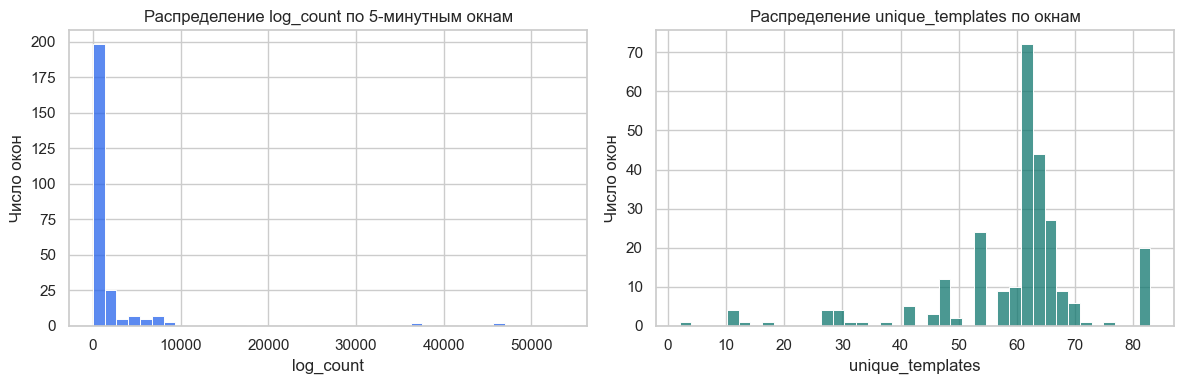

In [2]:
header = pd.read_csv(LOG_PATH, nrows=0).columns.tolist()
template_col = "DrainTemplate" if "DrainTemplate" in header else ("Template" if "Template" in header else "Content")

usecols = ["Timestamp", "Label", template_col]
if "Content" in header and "Content" not in usecols:
    usecols.append("Content")

raw_logs = pd.read_csv(LOG_PATH, usecols=usecols)
raw_logs["timestamp_num"] = pd.to_numeric(raw_logs["Timestamp"], errors="coerce")
raw_logs["label_num"] = pd.to_numeric(raw_logs["Label"], errors="coerce").fillna(0).gt(0).astype(int)
raw_logs["template_raw"] = raw_logs[template_col].fillna("").astype(str)

if "Content" in raw_logs.columns:
    empty_mask = raw_logs["template_raw"].str.strip().eq("")
    raw_logs.loc[empty_mask, "template_raw"] = raw_logs.loc[empty_mask, "Content"].fillna("").astype(str)

dup_key_cols = ["Timestamp"] + (["Content"] if "Content" in raw_logs.columns else [template_col])
pre_inversions = int((raw_logs["timestamp_num"].dropna().diff() < 0).sum())
pre_duplicates = int(raw_logs.duplicated(subset=dup_key_cols).sum())

clean_logs = raw_logs.dropna(subset=["timestamp_num"]).copy()
clean_logs = clean_logs.drop_duplicates(subset=dup_key_cols).copy()
clean_logs["timestamp"] = pd.to_datetime(clean_logs["timestamp_num"].astype("int64"), unit="s", utc=True)
clean_logs = clean_logs.sort_values("timestamp").reset_index(drop=True)
clean_logs["log_template"] = clean_logs["template_raw"].astype(str).str.strip()
clean_logs.loc[clean_logs["log_template"].eq(""), "log_template"] = "__EMPTY_TEMPLATE__"

post_inversions = int((clean_logs["timestamp"].diff() < pd.Timedelta(0)).sum())
post_duplicates = int(clean_logs.duplicated(subset=dup_key_cols).sum())

log_quality_df = pd.DataFrame(
    [
        {"Проверка": "Число строк", "До очистки": int(len(raw_logs)), "После очистки": int(len(clean_logs))},
        {"Проверка": "Пропуски timestamp", "До очистки": int(raw_logs["timestamp_num"].isna().sum()), "После очистки": 0},
        {"Проверка": "Дубликаты по ключу", "До очистки": pre_duplicates, "После очистки": post_duplicates},
        {"Проверка": "Инверсии времени", "До очистки": pre_inversions, "После очистки": post_inversions},
    ]
)

clean_logs["window_default"] = clean_logs["timestamp"].dt.floor(DEFAULT_WINDOW)
log_window_profile = (
    clean_logs.groupby("window_default", as_index=False)
    .agg(
        log_count=("log_template", "size"),
        unique_templates=("log_template", "nunique"),
        error_count=("label_num", "sum"),
    )
)

display(log_quality_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(log_window_profile["log_count"], bins=40, color="#2563eb", ax=axes[0])
axes[0].set_title("Распределение log_count по 5-минутным окнам")
axes[0].set_xlabel("log_count")
axes[0].set_ylabel("Число окон")

sns.histplot(log_window_profile["unique_templates"], bins=40, color="#0f766e", ax=axes[1])
axes[1].set_title("Распределение unique_templates по окнам")
axes[1].set_xlabel("unique_templates")
axes[1].set_ylabel("Число окон")

plt.tight_layout()
plt.show()

### Интерпретация результата

1. **Что показано.** В таблице зафиксирован эффект минимальной очистки логов, а на гистограммах — распределение двух базовых оконных характеристик: интенсивности потока и числа уникальных шаблонов.
2. **Что наблюдается.** Технические дефекты исходного потока — дубликаты и нарушения временного порядка — устраняются без разрушения содержательной структуры данных. После очистки оконные признаки сохраняют выраженную вариативность, то есть несут информацию, а не сводятся к тривиальному фону.
3. **Локальный вывод.** Логовая модальность может использоваться как устойчивая временная основа будущего датасета. Это особенно важно, поскольку именно на уровне окон далее будет происходить соединение логов с KPI.
4. **Почему это важно для ВКР.** Если логовая ось построена некорректно, то дальнейшая мультимодальная агрегация теряет надёжность уже на первом шаге. Поэтому качественная очистка логов является не технической деталью, а условием валидности всей дальнейшей постановки.


## 3. Обработка KPI-модальности в series-aware виде

KPI-модальность анализируется отдельно от логов, чтобы не потерять её внутреннюю структуру ещё до объединения источников. На этом этапе принципиально показать, что KPI следует хранить на уровне отдельных серий, а не схлопывать в чрезмерно грубые семейства признаков.

In [3]:
def detect_first_positive_start(label_series: pd.Series):
    labels = pd.to_numeric(label_series, errors="coerce").fillna(0).gt(0).astype(int)
    starts = labels[(labels.eq(1)) & (labels.shift(fill_value=0).eq(0))]
    return starts.index[0] if len(starts) else pd.NaT


def choose_kpi_files(scenario_dir: Path):
    labeled = sorted(scenario_dir.glob("*-labeled.csv"))
    if labeled:
        return labeled
    return sorted([p for p in scenario_dir.glob("*.csv") if not p.stem.endswith("-intersect")])


def scan_kpi_catalog(kpi_root: Path, sample_files_per_metric: int = 30):
    catalog_rows = []
    series_sample_rows = []
    metric_sample_counter = defaultdict(int)

    app_dirs = sorted([d for d in kpi_root.iterdir() if d.is_dir()])
    scenario_dirs = [sc for app in app_dirs for sc in sorted([d for d in app.iterdir() if d.is_dir()])]

    for scenario_dir in scenario_dirs:
        scenario_id = f"{scenario_dir.parent.name}/{scenario_dir.name}"
        files = choose_kpi_files(scenario_dir)

        fail_candidates = []
        global_min = pd.NaT
        global_max = pd.NaT
        channels = 0

        for csv_file in files:
            metric = csv_file.stem.split("-")[0]
            try:
                cols = pd.read_csv(csv_file, nrows=0).columns.tolist()
            except Exception:
                continue

            time_col = next((c for c in TIME_COLS if c in cols), None)
            if time_col is None:
                continue

            label_col = next((c for c in LABEL_COLS if c in cols), None)
            series_col = "series" if "series" in cols else None
            value_col = "value" if "value" in cols else None

            read_cols = [time_col]
            if label_col is not None:
                read_cols.append(label_col)
            if series_col is not None and value_col is not None:
                read_cols.extend([series_col, value_col])

            try:
                tmp = pd.read_csv(csv_file, usecols=list(dict.fromkeys(read_cols)))
            except Exception:
                continue

            tmp["time"] = pd.to_datetime(tmp[time_col], errors="coerce", utc=True)
            tmp = tmp.dropna(subset=["time"])
            if tmp.empty:
                continue

            local_min = tmp["time"].min()
            local_max = tmp["time"].max()
            global_min = local_min if pd.isna(global_min) else min(global_min, local_min)
            global_max = local_max if pd.isna(global_max) else max(global_max, local_max)

            if label_col is not None:
                label_series = pd.Series(
                    pd.to_numeric(tmp[label_col], errors="coerce").fillna(0).to_numpy(),
                    index=tmp["time"],
                ).groupby(level=0).max().sort_index()
                fail_start = detect_first_positive_start(label_series)
                if pd.notna(fail_start):
                    fail_candidates.append(fail_start)

            if series_col is not None and value_col is not None:
                series_names = (
                    tmp[series_col].dropna().astype(str).str.strip().replace("", np.nan).dropna().unique().tolist()
                )
                channels += len(series_names)

                allow_sample = metric_sample_counter[metric] < sample_files_per_metric
                if allow_sample:
                    tmp["value_num"] = pd.to_numeric(tmp[value_col], errors="coerce")
                    sample_part = tmp.dropna(subset=[series_col, "value_num"])
                    for s_name, g in sample_part.groupby(series_col):
                        values = g["value_num"]
                        series_sample_rows.append(
                            {
                                "metric": metric,
                                "series": str(s_name),
                                "n_obs": int(len(values)),
                                "median": float(values.median()),
                                "q95": float(values.quantile(0.95)),
                                "zero_share": float((values == 0).mean()),
                            }
                        )
                    metric_sample_counter[metric] += 1
            else:
                channels += 1

        fail_start_global = min(fail_candidates) if fail_candidates else pd.NaT
        duration_min = (
            float((global_max - global_min) / pd.Timedelta(minutes=1))
            if pd.notna(global_min) and pd.notna(global_max)
            else np.nan
        )

        catalog_rows.append(
            {
                "scenario_id": scenario_id,
                "scenario_dir": str(scenario_dir),
                "fail_start": fail_start_global,
                "time_min": global_min,
                "time_max": global_max,
                "duration_min": duration_min,
                "files_used": int(len(files)),
                "series_channels": int(channels),
            }
        )

    catalog_df = pd.DataFrame(catalog_rows).sort_values("scenario_id").reset_index(drop=True)
    series_sample_df = pd.DataFrame(series_sample_rows)
    return catalog_df, series_sample_df


kpi_catalog_df, kpi_series_sample_df = scan_kpi_catalog(KPI_ROOT, sample_files_per_metric=30)

kpi_overview_df = pd.DataFrame(
    [
        {"Показатель": "Приложений", "Значение": int(kpi_catalog_df["scenario_id"].str.split("/").str[0].nunique())},
        {"Показатель": "Сценариев", "Значение": int(len(kpi_catalog_df))},
        {"Показатель": "Сценариев с fail_start", "Значение": int(kpi_catalog_df["fail_start"].notna().sum())},
        {"Показатель": "Медианная длительность (мин)", "Значение": round(float(kpi_catalog_df["duration_min"].median()), 2)},
        {"Показатель": "P90 длительности (мин)", "Значение": round(float(kpi_catalog_df["duration_min"].quantile(0.9)), 2)},
        {"Показатель": "Медиана series_channels", "Значение": int(kpi_catalog_df["series_channels"].median())},
    ]
)

if not kpi_series_sample_df.empty:
    kpi_series_profile_df = (
        kpi_series_sample_df
        .groupby(["metric", "series"], as_index=False)
        .agg(
            files_sampled=("n_obs", "size"),
            median=("median", "median"),
            q95=("q95", "median"),
            zero_share=("zero_share", "mean"),
        )
        .sort_values(["metric", "zero_share"], ascending=[True, False])
    )
else:
    kpi_series_profile_df = pd.DataFrame(columns=["metric", "series", "files_sampled", "median", "q95", "zero_share"])

display(kpi_overview_df)
display(kpi_series_profile_df.head(14))

,Показатель,Значение
0,Приложений,21.00
1,Сценариев,587.00
2,Сценариев с fail_start,208.00
3,Медианная длительность (мин),1.22
4,P90 длительности (мин),4.03
5,Медиана series_channels,13.00


,metric,series,files_sampled,median,q95,zero_share
1,cpu,iowait,30,0.0500,5.45025,0.375443
0,cpu,idle,30,87.3850,99.25000,0.004050
3,cpu,user,30,9.5775,45.92275,0.000838
2,cpu,system,30,0.9900,5.31900,0.000000
7,iostat,w_await,23,0.0000,235.64800,0.585760
4,iostat,r_await,23,2.6700,97.40000,0.406586
5,iostat,rkB_s,30,15.0000,744.21150,0.350116
8,iostat,wkB_s,30,275.0000,173165.00000,0.341512
6,iostat,util,30,1.8000,100.00000,0.288216
9,memstat,commit,30,17.9200,23.83000,0.015032


### Интерпретация результата

1. **Что показано.** Сводная таблица описывает общий профиль KPI-каталога, а расширенная таблица по сериям демонстрирует различия между каналами внутри отдельных метрик.
2. **Что наблюдается.** KPI неоднородны сразу по нескольким измерениям: по длительности сценариев, по числу доступных серий, по масштабу значений и по доле нулевых наблюдений. Иными словами, внутри KPI-модальности уже содержится собственная структура, которую нельзя без потерь свести к усреднённым семейным агрегатам.
3. **Локальный вывод.** Корректный pipeline должен сохранять KPI в series-aware формате и сопровождать эти признаки индикаторами доступности. Только при таком подходе вторая модальность остаётся содержательно самостоятельной.
4. **Почему это важно для ВКР.** Если KPI грубо схлопываются ещё на этапе подготовки данных, то последующая мультимодальная система оказывается формально двухмодальной, но фактически лишённой полноценной KPI-ветки. Для ВКР важно избежать именно этого упрощения.


## 4. Multi-rate выравнивание: macro 5min и micro 10s/30s

Вместо глобального выбора единственного `window` для всех шагов вводится двухконтурная схема: macro-ось фиксируется на `5min` (контекст логов), а micro-ось строится на `10s/30s` (локальная динамика перед сбоем). В этом разделе подбирается только `tolerance` сопоставления run'ов log↔KPI и оценивается ожидаемое мультимодальное покрытие уже в micro-шкале.

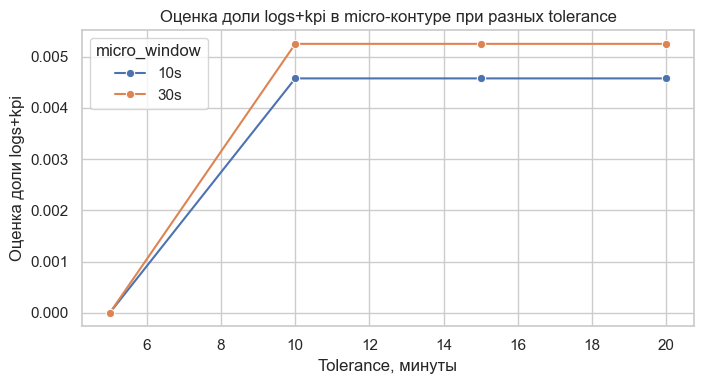

,macro_window,tolerance_min,log_runs,matched_runs,match_rate,both_share_10s_est,both_share_30s_est,micro_share_mean_est
0,5min,15,16,4,0.2500,0.0046,0.0053,0.0049
1,5min,20,16,4,0.2500,0.0046,0.0053,0.0049
2,5min,10,16,3,0.1875,0.0046,0.0053,0.0049
3,5min,5,16,2,0.1250,0.0000,0.0000,0.0000


In [4]:
def make_run_windows(fail_start: pd.Timestamp, window: str):
    start = (fail_start - pd.Timedelta(minutes=BASELINE_FROM_MIN)).floor(window)
    end = (fail_start - pd.Timedelta(minutes=LEAD_TO_MIN)).floor(window)
    if end < start:
        return pd.DatetimeIndex([], tz="UTC")
    return pd.date_range(start=start, end=end, freq=window)


def infer_log_runs(logs: pd.DataFrame, window: str):
    temp = logs.copy()
    temp["window"] = temp["timestamp"].dt.floor(window)

    window_labels = temp.groupby("window")["label_num"].max().sort_index()
    window_counts = temp.groupby("window").size()

    fail_starts = window_labels[(window_labels.eq(1)) & (window_labels.shift(fill_value=0).eq(0))].index

    rows = []
    run_windows = {}

    for i, fail_start in enumerate(fail_starts, start=1):
        idx = make_run_windows(fail_start, window)
        if len(idx) == 0:
            continue

        counts = window_counts.reindex(idx).fillna(0)
        pre_mask = (idx >= fail_start - pd.Timedelta(minutes=LEAD_FROM_MIN)) & (idx < fail_start - pd.Timedelta(minutes=LEAD_TO_MIN))

        baseline_nonzero = int(counts[~pre_mask].gt(0).sum())
        prefail_nonzero = int(counts[pre_mask].gt(0).sum())

        if baseline_nonzero < 1 or prefail_nonzero < 1:
            continue

        run_id = f"log_run_{i:03d}_{fail_start.strftime('%Y%m%d_%H%M')}"
        run_windows[run_id] = idx

        rows.append(
            {
                "run_id": run_id,
                "fail_start": fail_start,
                "baseline_windows_with_logs": baseline_nonzero,
                "prefail_windows_with_logs": prefail_nonzero,
                "window_total": int(len(idx)),
            }
        )

    if not rows:
        run_meta = pd.DataFrame(
            columns=[
                "run_id",
                "fail_start",
                "baseline_windows_with_logs",
                "prefail_windows_with_logs",
                "window_total",
            ]
        )
        return run_meta, {}

    run_meta = pd.DataFrame(rows).sort_values("fail_start").reset_index(drop=True)
    return run_meta, run_windows


def match_log_runs_to_kpi(log_runs: pd.DataFrame, kpi_catalog: pd.DataFrame, window: str, tolerance_min: int):
    if log_runs.empty:
        return pd.DataFrame(columns=["run_id", "fail_start", "kpi_run_id", "matched", "match_delta_min", "kpi_time_min", "kpi_time_max"])

    candidates = kpi_catalog[kpi_catalog["fail_start"].notna()].copy().reset_index(drop=True)
    if candidates.empty:
        out = log_runs[["run_id", "fail_start"]].copy()
        out["kpi_run_id"] = pd.NA
        out["matched"] = False
        out["match_delta_min"] = np.nan
        out["kpi_time_min"] = pd.NaT
        out["kpi_time_max"] = pd.NaT
        return out

    candidates["fail_start_w"] = candidates["fail_start"].dt.floor(window)
    tolerance = pd.Timedelta(minutes=tolerance_min)

    available = set(candidates.index.tolist())
    rows = []

    for row in log_runs.sort_values("fail_start").itertuples(index=False):
        best_idx = None
        best_delta = None

        for idx in list(available):
            delta = abs(candidates.at[idx, "fail_start_w"] - row.fail_start)
            if pd.isna(delta):
                continue
            if (best_delta is None) or (delta < best_delta):
                best_delta = delta
                best_idx = idx

        if best_idx is not None and best_delta <= tolerance:
            available.remove(best_idx)
            rows.append(
                {
                    "run_id": row.run_id,
                    "fail_start": row.fail_start,
                    "kpi_run_id": candidates.at[best_idx, "scenario_id"],
                    "matched": True,
                    "match_delta_min": float(best_delta / pd.Timedelta(minutes=1)),
                    "kpi_time_min": candidates.at[best_idx, "time_min"],
                    "kpi_time_max": candidates.at[best_idx, "time_max"],
                }
            )
        else:
            rows.append(
                {
                    "run_id": row.run_id,
                    "fail_start": row.fail_start,
                    "kpi_run_id": pd.NA,
                    "matched": False,
                    "match_delta_min": np.nan,
                    "kpi_time_min": pd.NaT,
                    "kpi_time_max": pd.NaT,
                }
            )

    return pd.DataFrame(rows)


def estimate_micro_overlap_share(log_runs: pd.DataFrame, matched_df: pd.DataFrame, micro_window: str):
    if log_runs.empty:
        return np.nan

    matched_map = matched_df.set_index("run_id")[["matched", "kpi_time_min", "kpi_time_max"]]
    total_points = 0
    points_with_kpi = 0

    for row in log_runs.itertuples(index=False):
        idx = pd.date_range(
            start=row.fail_start - pd.Timedelta(minutes=BASELINE_FROM_MIN),
            end=row.fail_start - pd.Timedelta(minutes=LEAD_TO_MIN),
            freq=micro_window,
        )
        if len(idx) == 0:
            continue

        total_points += len(idx)
        if row.run_id not in matched_map.index:
            continue

        item = matched_map.loc[row.run_id]
        is_matched = bool(item["matched"]) if pd.notna(item["matched"]) else False
        if (not is_matched) or pd.isna(item["kpi_time_min"]) or pd.isna(item["kpi_time_max"]):
            continue

        left = pd.Timestamp(item["kpi_time_min"]).floor(micro_window)
        right = pd.Timestamp(item["kpi_time_max"]).ceil(micro_window)
        points_with_kpi += int(((idx >= left) & (idx <= right)).sum())

    return float(points_with_kpi / total_points) if total_points > 0 else np.nan


log_runs_macro, run_windows_macro = infer_log_runs(clean_logs, MACRO_WINDOW)

alignment_rows = []
for tolerance_min in TOLERANCE_CANDIDATES:
    matched_df = match_log_runs_to_kpi(log_runs_macro, kpi_catalog_df, window=MACRO_WINDOW, tolerance_min=tolerance_min)

    row = {
        "macro_window": MACRO_WINDOW,
        "tolerance_min": int(tolerance_min),
        "log_runs": int(len(log_runs_macro)),
        "matched_runs": int(matched_df["matched"].sum()) if not matched_df.empty else 0,
        "match_rate": float(matched_df["matched"].mean()) if not matched_df.empty else np.nan,
    }

    for micro_window in MICRO_WINDOWS:
        row[f"both_share_{micro_window}_est"] = estimate_micro_overlap_share(log_runs_macro, matched_df, micro_window)

    alignment_rows.append(row)

alignment_multirate_df = pd.DataFrame(alignment_rows)
if alignment_multirate_df.empty:
    raise RuntimeError("Не удалось рассчитать grid tolerance для multi-rate выравнивания")

micro_share_cols = [f"both_share_{w}_est" for w in MICRO_WINDOWS]
alignment_multirate_df["micro_share_mean_est"] = alignment_multirate_df[micro_share_cols].mean(axis=1)
alignment_multirate_df = alignment_multirate_df.sort_values(["micro_share_mean_est", "matched_runs"], ascending=False).reset_index(drop=True)
selected_tolerance = int(alignment_multirate_df.iloc[0]["tolerance_min"])

plot_df = alignment_multirate_df.melt(
    id_vars=["tolerance_min"],
    value_vars=micro_share_cols,
    var_name="micro_window",
    value_name="both_share_est",
)
plot_df["micro_window"] = plot_df["micro_window"].str.replace("both_share_", "", regex=False).str.replace("_est", "", regex=False)

plt.figure(figsize=(7.2, 4.0))
sns.lineplot(data=plot_df, x="tolerance_min", y="both_share_est", hue="micro_window", marker="o")
plt.title("Оценка доли logs+kpi в micro-контуре при разных tolerance")
plt.xlabel("Tolerance, минуты")
plt.ylabel("Оценка доли logs+kpi")
plt.tight_layout()
plt.show()

alignment_report_df = alignment_multirate_df[[
    "macro_window",
    "tolerance_min",
    "log_runs",
    "matched_runs",
    "match_rate",
] + micro_share_cols + ["micro_share_mean_est"]].copy()

for col in ["match_rate", "micro_share_mean_est"] + micro_share_cols:
    alignment_report_df[col] = alignment_report_df[col].astype(float).round(4)

display(alignment_report_df)

### Интерпретация результата

1. **Что показано.** Таблица фиксирует результат подбора `tolerance` при фиксированном macro-окне `5min` и двух micro-шкалах (`10s`, `30s`). График показывает, как изменяется ожидаемая доля `logs+kpi` точек в micro-контуре.
2. **Что наблюдается.** Даже после перехода к multi-rate схеме покрытие мультимодальности остаётся чувствительным к `tolerance`, а абсолютные значения доли `logs+kpi` не становятся автоматически высокими. Это подтверждает ограниченность KPI-покрытия, выявленную в EDA.
3. **Локальный вывод.** В `02` выбирается не «лучшая модель», а рабочий параметр согласования для дальнейшей сборки датасета: `macro=5min` фиксируется как контекстная ось, а `tolerance` подбирается по micro-покрытию.
4. **Почему это важно для ВКР.** Такой шаг показывает инженерную добросовестность: мультимодальность не декларируется, а измеряется и ограничивается фактической доступностью данных.


## 5. Сборка multi-rate датасета, dual-target разметка и leakage-control

В этом шаге строится финальный baseline-датасет: для каждого run формируются micro-точки (`10s` и `30s`) с KPI-динамикой и интенсивностью логов, к которым подмешивается macro-контекст (`5min`). Далее добавляются две цели (`y_warning`, `y_risk`), hard negatives (`kpi_available=1`, `y=0`) и выполняется group-aware split с балансировкой train по `(state × kpi_available × run_id)`.

In [5]:
def load_kpi_wide_series_aware(scenario_dir: Path, window: str):
    files = choose_kpi_files(scenario_dir)
    metric_frames = []
    label_frames = []

    for csv_file in files:
        metric = csv_file.stem.split("-")[0]
        try:
            raw = pd.read_csv(csv_file)
        except Exception:
            continue

        time_col = next((c for c in TIME_COLS if c in raw.columns), None)
        if time_col is None:
            continue

        raw["time"] = pd.to_datetime(raw[time_col], errors="coerce", utc=True)
        raw = raw.dropna(subset=["time"]).sort_values("time")
        if raw.empty:
            continue

        label_col = next((c for c in LABEL_COLS if c in raw.columns), None)

        if {"series", "value"}.issubset(raw.columns):
            tmp = raw[["time", "series", "value"]].copy()
            tmp["value"] = pd.to_numeric(tmp["value"], errors="coerce")
            tmp = tmp.dropna(subset=["series", "value"])
            if not tmp.empty:
                wide = tmp.pivot_table(index="time", columns="series", values="value", aggfunc="mean")
                wide = wide.resample(window).mean()
                wide.columns = [f"{metric}__{str(col)}" for col in wide.columns]
                metric_frames.append(wide)
        else:
            numeric_cols = []
            excluded = set(TIME_COLS + LABEL_COLS + ["series", "value", "time"])
            for col in raw.columns:
                if col in excluded:
                    continue
                series = pd.to_numeric(raw[col], errors="coerce")
                if series.notna().any():
                    raw[col] = series
                    numeric_cols.append(col)

            if numeric_cols:
                wide = raw.set_index("time")[numeric_cols].resample(window).mean()
                wide.columns = [f"{metric}__{col}" for col in numeric_cols]
                metric_frames.append(wide)

        if label_col is not None:
            lbl = pd.Series(
                pd.to_numeric(raw[label_col], errors="coerce").fillna(0).to_numpy(),
                index=raw["time"],
            ).groupby(level=0).max().sort_index()
            label_frames.append(lbl.resample(window).max().rename(f"{metric}__label"))

    if metric_frames:
        kpi_wide = pd.concat(metric_frames, axis=1).sort_index()
        kpi_wide = kpi_wide.loc[:, ~kpi_wide.columns.duplicated()]
    else:
        kpi_wide = pd.DataFrame(index=pd.DatetimeIndex([], tz="UTC"))

    if label_frames:
        labels = pd.concat(label_frames, axis=1).max(axis=1).sort_index()
        fail_start = detect_first_positive_start(labels)
    else:
        fail_start = pd.NaT

    return {"kpi": kpi_wide, "fail_start": fail_start}


def assign_overlap_groups(run_windows: dict):
    run_ids = list(run_windows.keys())
    if not run_ids:
        return {}, {}

    parent = {rid: rid for rid in run_ids}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    run_sets = {rid: set(idx) for rid, idx in run_windows.items()}
    for i, rid in enumerate(run_ids):
        for other in run_ids[i + 1:]:
            if run_sets[rid].intersection(run_sets[other]):
                union(rid, other)

    roots = sorted({find(rid) for rid in run_ids})
    root_to_episode = {root: f"episode_{i:02d}" for i, root in enumerate(roots, start=1)}

    run_to_episode = {rid: root_to_episode[find(rid)] for rid in run_ids}
    episode_sizes = pd.Series(run_to_episode).value_counts().to_dict()
    return run_to_episode, episode_sizes


def make_valid_group_split(
    df: pd.DataFrame,
    target_col: str = "y_warning",
    group_col: str = "episode_id",
    test_size: float = 0.3,
    n_splits: int = 250,
    random_state: int = 42,
    min_train_kpi: int = 1,
    min_train_both: int = 1,
    min_test_kpi: int = 1,
    min_test_both: int = 1,
):
    splitter = GroupShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=random_state)
    best_pair = None
    best_score = (-1, -1, -1, -1)

    for train_idx, test_idx in splitter.split(df, df[target_col], groups=df[group_col]):
        train_part = df.iloc[train_idx].copy()
        test_part = df.iloc[test_idx].copy()

        class_ok = train_part[target_col].nunique() == 2 and test_part[target_col].nunique() == 2
        if not class_ok:
            continue

        train_kpi = int(train_part["kpi_available"].sum())
        train_both = int(train_part["has_both_modalities"].sum())
        test_kpi = int(test_part["kpi_available"].sum())
        test_both = int(test_part["has_both_modalities"].sum())
        score = (test_kpi, test_both, train_kpi, train_both)

        if score > best_score:
            best_score = score
            best_pair = (train_part, test_part)

        if (
            train_kpi >= min_train_kpi
            and train_both >= min_train_both
            and test_kpi >= min_test_kpi
            and test_both >= min_test_both
        ):
            return train_part, test_part, True

    if best_pair is None:
        raise RuntimeError("Не удалось найти group-aware split с двумя классами для целевой переменной")

    return best_pair[0], best_pair[1], False


def make_micro_index(fail_start: pd.Timestamp, micro_window: str):
    start = fail_start - pd.Timedelta(minutes=BASELINE_FROM_MIN)
    end = fail_start - pd.Timedelta(minutes=LEAD_TO_MIN)
    if end < start:
        return pd.DatetimeIndex([], tz="UTC")
    return pd.date_range(start=start, end=end, freq=micro_window)


def build_log_micro_features(run_logs: pd.DataFrame, idx: pd.DatetimeIndex, micro_window: str):
    if run_logs.empty:
        micro = pd.DataFrame(
            index=idx,
            data={
                "micro_log_count": 0.0,
                "micro_unique_templates": 0.0,
                "micro_error_count": 0.0,
            },
        )
    else:
        micro = (
            run_logs.set_index("timestamp")
            .resample(micro_window)
            .agg(
                micro_log_count=("log_template", "size"),
                micro_unique_templates=("log_template", "nunique"),
                micro_error_count=("label_num", "sum"),
            )
        )
        micro = micro.reindex(idx).fillna(0.0)

    window_sec = max(float(pd.Timedelta(micro_window).total_seconds()), 1.0)
    micro["micro_log_rate"] = micro["micro_log_count"] / window_sec
    micro["micro_error_rate"] = np.where(
        micro["micro_log_count"].gt(0),
        micro["micro_error_count"] / micro["micro_log_count"],
        0.0,
    )
    return micro


def build_kpi_micro_features(run_kpi: pd.DataFrame):
    out = pd.DataFrame(index=run_kpi.index)

    if run_kpi.shape[1] == 0:
        out["kpi_available"] = 0
        out["kpi_feature_count"] = 0
        out["kpi_avail_ratio"] = 0.0
        out["kpi_last"] = np.nan
        out["kpi_mean"] = np.nan
        out["kpi_roll_mean_60"] = np.nan
        out["kpi_roll_mean_120"] = np.nan
        out["kpi_delta_60"] = np.nan
        out["kpi_delta_120"] = np.nan
        out["kpi_slope_60"] = np.nan
        out["kpi_slope_120"] = np.nan
        out["kpi_recency_sec"] = 1e6
        return out

    numeric = run_kpi.apply(pd.to_numeric, errors="coerce")
    avail_mask = numeric.notna()

    out["kpi_available"] = avail_mask.any(axis=1).astype(int)
    out["kpi_feature_count"] = avail_mask.sum(axis=1).astype(int)
    out["kpi_avail_ratio"] = avail_mask.mean(axis=1).astype(float)

    channel_mean = numeric.mean(axis=1, skipna=True)
    channel_last = numeric.ffill().mean(axis=1, skipna=True)

    out["kpi_mean"] = channel_mean
    out["kpi_last"] = channel_last

    out["kpi_roll_mean_60"] = channel_last.rolling("60s", min_periods=1).mean()
    out["kpi_roll_mean_120"] = channel_last.rolling("120s", min_periods=1).mean()
    out["kpi_delta_60"] = out["kpi_last"] - out["kpi_roll_mean_60"]
    out["kpi_delta_120"] = out["kpi_last"] - out["kpi_roll_mean_120"]
    out["kpi_slope_60"] = out["kpi_delta_60"] / 60.0
    out["kpi_slope_120"] = out["kpi_delta_120"] / 120.0

    observed_ns = pd.Series(np.where(out["kpi_available"].eq(1), out.index.asi8, np.nan), index=out.index).ffill()
    current_ns = pd.Series(out.index.asi8, index=out.index)
    out["kpi_recency_sec"] = ((current_ns - observed_ns) / 1e9).fillna(1e6).clip(upper=1e6)

    return out


def rebalance_train_triplet(train_df: pd.DataFrame, random_state: int = 42):
    key_cols = ["state", "kpi_available", "run_id"]
    group_sizes = train_df.groupby(key_cols, dropna=False).size()
    if group_sizes.empty:
        return train_df.copy()

    target_n = int(np.clip(group_sizes.median(), 20, 120))
    rng = np.random.default_rng(random_state)
    chunks = []

    for _, part in train_df.groupby(key_cols, dropna=False):
        seed = int(rng.integers(1, 1_000_000))
        if len(part) >= target_n:
            sampled = part.sample(n=target_n, random_state=seed)
        else:
            sampled = part.sample(n=target_n, replace=True, random_state=seed)
        chunks.append(sampled)

    balanced = pd.concat(chunks, ignore_index=True)

    hard_mask = balanced["hard_negative"].eq(1)
    if hard_mask.any():
        hard_pool = balanced.loc[hard_mask]
        hard_target = max(int(0.2 * len(balanced)), 1)
        seed = int(rng.integers(1, 1_000_000))
        hard_extra = hard_pool.sample(n=hard_target, replace=True, random_state=seed)
        balanced = pd.concat([balanced, hard_extra], ignore_index=True)

    return balanced.sample(frac=1.0, random_state=random_state).reset_index(drop=True)


run_meta_macro = log_runs_macro.copy()
match_macro = match_log_runs_to_kpi(run_meta_macro, kpi_catalog_df, MACRO_WINDOW, selected_tolerance)
run_meta_macro = run_meta_macro.merge(match_macro, on=["run_id", "fail_start"], how="left")

tmp_logs = clean_logs.copy()
tmp_logs["macro_window"] = tmp_logs["timestamp"].dt.floor(MACRO_WINDOW)
macro_log_context = (
    tmp_logs.groupby("macro_window")
    .agg(
        macro_log_count=("log_template", "size"),
        macro_unique_templates=("log_template", "nunique"),
        macro_error_count=("label_num", "sum"),
    )
    .sort_index()
)

kpi_cache = {}
matched_scenarios = sorted(run_meta_macro.loc[run_meta_macro["matched"], "kpi_run_id"].dropna().unique().tolist())
for scenario_id in matched_scenarios:
    scenario_dir = Path(kpi_catalog_df.loc[kpi_catalog_df["scenario_id"].eq(scenario_id), "scenario_dir"].iloc[0])
    kpi_cache[scenario_id] = {}
    for micro_window in MICRO_WINDOWS:
        kpi_cache[scenario_id][micro_window] = load_kpi_wide_series_aware(scenario_dir, micro_window)["kpi"]

frames = []
for row in run_meta_macro.itertuples(index=False):
    run_start = row.fail_start - pd.Timedelta(minutes=BASELINE_FROM_MIN)
    run_end = row.fail_start - pd.Timedelta(minutes=LEAD_TO_MIN)
    run_logs = clean_logs[(clean_logs["timestamp"] >= run_start) & (clean_logs["timestamp"] <= run_end)].copy()

    for micro_window in MICRO_WINDOWS:
        idx = make_micro_index(row.fail_start, micro_window)
        if len(idx) == 0:
            continue

        frame = pd.DataFrame(index=idx)
        frame.index.name = "micro_ts"
        frame["run_id"] = row.run_id
        frame["fail_start"] = row.fail_start
        frame["micro_window"] = micro_window
        frame["micro_window_sec"] = int(pd.Timedelta(micro_window).total_seconds())
        frame["kpi_run_id"] = row.kpi_run_id if isinstance(row.kpi_run_id, str) else pd.NA

        log_micro = build_log_micro_features(run_logs, idx, micro_window)
        frame = frame.join(log_micro, how="left")

        macro_idx = idx.floor(MACRO_WINDOW)
        macro_part = macro_log_context.reindex(macro_idx).fillna(0.0)
        macro_part.index = idx
        frame = frame.join(macro_part, how="left")

        if isinstance(row.kpi_run_id, str) and row.kpi_run_id in kpi_cache:
            run_kpi = kpi_cache[row.kpi_run_id][micro_window].reindex(idx)
        else:
            run_kpi = pd.DataFrame(index=idx)

        kpi_micro = build_kpi_micro_features(run_kpi)
        frame = frame.join(kpi_micro, how="left")

        frame["minutes_before_fail"] = ((row.fail_start - idx) / pd.Timedelta(minutes=1)).astype(float)
        frame["recency_to_fail_min"] = frame["minutes_before_fail"]
        frame["run_progress"] = 1.0 - (frame["minutes_before_fail"] / BASELINE_FROM_MIN).clip(lower=0, upper=1)

        frame["y_warning"] = (
            (frame["minutes_before_fail"] <= WARNING_FROM_MIN)
            & (frame["minutes_before_fail"] > WARNING_TO_MIN)
        ).astype(int)
        frame["y_risk"] = (
            (frame["minutes_before_fail"] <= RISK_FROM_MIN)
            & (frame["minutes_before_fail"] > RISK_TO_MIN)
        ).astype(int)
        frame["y_anomaly"] = frame["y_risk"]

        frame["state"] = np.select(
            [frame["y_risk"].eq(1), frame["y_warning"].eq(1)],
            ["risk", "warning"],
            default="normal",
        )

        frame["has_both_modalities"] = ((frame["micro_log_count"] > 0) & frame["kpi_available"].eq(1)).astype(int)
        frame["modality_state"] = np.select(
            [
                frame["micro_log_count"].gt(0) & frame["kpi_available"].eq(1),
                frame["micro_log_count"].gt(0) & frame["kpi_available"].eq(0),
                frame["micro_log_count"].eq(0) & frame["kpi_available"].eq(1),
            ],
            ["logs+kpi", "logs_only", "kpi_only"],
            default="none",
        )

        frame["hard_negative"] = (
            frame["kpi_available"].eq(1)
            & frame["y_warning"].eq(0)
            & frame["y_risk"].eq(0)
        ).astype(int)

        frame["micro_ts"] = idx
        frames.append(frame.reset_index(drop=True))

if not frames:
    raise RuntimeError("Не удалось собрать ни одной строки multi-rate датасета")

dataset = pd.concat(frames, ignore_index=True)

numeric_candidate_cols = [
    "micro_window_sec",
    "micro_log_count",
    "micro_unique_templates",
    "micro_error_count",
    "micro_log_rate",
    "micro_error_rate",
    "macro_log_count",
    "macro_unique_templates",
    "macro_error_count",
    "kpi_available",
    "kpi_feature_count",
    "kpi_avail_ratio",
    "kpi_last",
    "kpi_mean",
    "kpi_roll_mean_60",
    "kpi_roll_mean_120",
    "kpi_delta_60",
    "kpi_delta_120",
    "kpi_slope_60",
    "kpi_slope_120",
    "kpi_recency_sec",
    "minutes_before_fail",
    "recency_to_fail_min",
    "run_progress",
    "has_both_modalities",
    "hard_negative",
    "y_warning",
    "y_risk",
    "y_anomaly",
]

for col in numeric_candidate_cols:
    if col in dataset.columns:
        dataset[col] = pd.to_numeric(dataset[col], errors="coerce")

run_to_episode, episode_sizes = assign_overlap_groups(run_windows_macro)
dataset["episode_id"] = dataset["run_id"].map(run_to_episode)
dataset["episode_size"] = dataset["episode_id"].map(episode_sizes)

train_df, test_df, strict_slice_split = make_valid_group_split(
    dataset,
    target_col="y_warning",
    group_col="episode_id",
    test_size=0.3,
    n_splits=250,
    random_state=42,
)

train_df = train_df.copy()
test_df = test_df.copy()
train_df["window_key"] = train_df["micro_window"].astype(str) + "|" + train_df["micro_ts"].astype(str)
test_df["window_key"] = test_df["micro_window"].astype(str) + "|" + test_df["micro_ts"].astype(str)

shared_windows = set(train_df["window_key"]).intersection(set(test_df["window_key"]))
state_conflicts = 0
if shared_windows:
    train_state = train_df.groupby("window_key")["state"].agg(lambda s: "|".join(sorted(set(s))))
    test_state = test_df.groupby("window_key")["state"].agg(lambda s: "|".join(sorted(set(s))))
    state_conflicts = int(sum(train_state.get(k) != test_state.get(k) for k in shared_windows))

train_balanced_df = rebalance_train_triplet(train_df, random_state=42)

warning_mask = dataset["y_warning"].eq(1)
both_warning_share = float(dataset.loc[warning_mask, "has_both_modalities"].mean()) if warning_mask.any() else np.nan

dataset_passport_df = pd.DataFrame(
    [
        {"Факт": "Macro window", "Значение": MACRO_WINDOW},
        {"Факт": "Micro windows", "Значение": ", ".join(MICRO_WINDOWS)},
        {"Факт": "Tolerance (мин)", "Значение": selected_tolerance},
        {"Факт": "Log-run в выборке", "Значение": int(run_meta_macro.shape[0])},
        {"Факт": "Сопоставлено с KPI-run", "Значение": int(run_meta_macro["matched"].sum())},
        {"Факт": "Строк в multi-rate датасете", "Значение": int(len(dataset))},
        {"Факт": "Положительных y_warning", "Значение": int(dataset["y_warning"].sum())},
        {"Факт": "Положительных y_risk", "Значение": int(dataset["y_risk"].sum())},
        {"Факт": "Hard negatives (kpi=1, y=0)", "Значение": int(dataset["hard_negative"].sum())},
        {"Факт": "Доля kpi_available=1", "Значение": round(float(dataset["kpi_available"].mean()), 4)},
        {"Факт": "Доля has_both_modalities=1", "Значение": round(float(dataset["has_both_modalities"].mean()), 4)},
        {"Факт": "Доля has_both в y_warning", "Значение": round(float(both_warning_share), 4) if pd.notna(both_warning_share) else np.nan},
    ]
)

split_integrity_df = pd.DataFrame(
    [
        {"Проверка": "Группы split", "Значение": f"episode_id = {dataset['episode_id'].nunique()}"},
        {"Проверка": "Train/Test строк (до балансировки)", "Значение": f"{len(train_df)} / {len(test_df)}"},
        {"Проверка": "Train строк (после балансировки)", "Значение": int(len(train_balanced_df))},
        {"Проверка": "y_warning positives train/test", "Значение": f"{int(train_df['y_warning'].sum())} / {int(test_df['y_warning'].sum())}"},
        {"Проверка": "y_risk positives train/test", "Значение": f"{int(train_df['y_risk'].sum())} / {int(test_df['y_risk'].sum())}"},
        {"Проверка": "kpi_available train/test", "Значение": f"{int(train_df['kpi_available'].sum())} / {int(test_df['kpi_available'].sum())}"},
        {"Проверка": "has_both train/test", "Значение": f"{int(train_df['has_both_modalities'].sum())} / {int(test_df['has_both_modalities'].sum())}"},
        {"Проверка": "Shared micro windows train-test", "Значение": int(len(shared_windows))},
        {"Проверка": "Shared windows with state conflict", "Значение": int(state_conflicts)},
        {"Проверка": "Строгий split train+test KPI", "Значение": bool(strict_slice_split)},
    ]
)

train_profile_raw = train_df.groupby(["state", "kpi_available"]).size().rename("train_raw")
train_profile_bal = train_balanced_df.groupby(["state", "kpi_available"]).size().rename("train_balanced")
train_balance_profile_df = pd.concat([train_profile_raw, train_profile_bal], axis=1).fillna(0).astype(int).reset_index()

micro_coverage_df = (
    dataset.groupby("micro_window", as_index=False)
    .agg(
        rows=("run_id", "size"),
        y_warning_share=("y_warning", "mean"),
        y_risk_share=("y_risk", "mean"),
        kpi_available_share=("kpi_available", "mean"),
        both_share=("has_both_modalities", "mean"),
        hard_negative_rows=("hard_negative", "sum"),
    )
)
for col in ["y_warning_share", "y_risk_share", "kpi_available_share", "both_share"]:
    micro_coverage_df[col] = micro_coverage_df[col].astype(float).round(4)

display(dataset_passport_df)
display(split_integrity_df)
display(train_balance_profile_df)
display(micro_coverage_df)

,Факт,Значение
0,Macro window,5min
1,Micro windows,"10s, 30s"
2,Tolerance (мин),15
3,Log-run в выборке,16
4,Сопоставлено с KPI-run,4
5,Строк в multi-rate датасете,7584
6,Положительных y_warning,1280
7,Положительных y_risk,512
8,"Hard negatives (kpi=1, y=0)",0
9,Доля kpi_available=1,0.0045


,Проверка,Значение
0,Группы split,episode_id = 10
1,Train/Test строк (до балансировки),4740 / 2844
2,Train строк (после балансировки),2400
3,y_warning positives train/test,800 / 480
4,y_risk positives train/test,320 / 192
5,kpi_available train/test,0 / 34
6,has_both train/test,0 / 14
7,Shared micro windows train-test,0
8,Shared windows with state conflict,0
9,Строгий split train+test KPI,False


,state,kpi_available,train_raw,train_balanced
0,normal,0,3620,800
1,risk,0,320,800
2,warning,0,800,800


,micro_window,rows,y_warning_share,y_risk_share,kpi_available_share,both_share,hard_negative_rows
0,10s,5680,0.1690,0.0676,0.0044,0.0014,0
1,30s,1904,0.1681,0.0672,0.0047,0.0032,0


### Интерпретация результата

1. **Что показано.** В паспорте датасета зафиксированы параметры multi-rate сборки (`macro=5min`, `micro=10s/30s`, выбранный `tolerance`), объём dual-target разметки (`y_warning`, `y_risk`) и масштаб hard negatives при `kpi_available=1`.
2. **Что наблюдается.** Group-aware split по overlap-эпизодам сохраняется, а train дополнительно балансируется по тройке `(state × kpi_available × run_id)`. В таблице целостности отдельно фиксируется, удалось ли получить строгий split с KPI-покрытием одновременно в train и test; если нет, это явно отмечается как ограничение данных, а не скрывается.
3. **Локальный вывод.** Сборка baseline-контурa теперь включает ключевые элементы, необходимые для `03`: multi-rate признаки, missing-aware индикаторы, dual-target разметку и контроль shortcut через явный учёт доступности KPI.
4. **Почему это важно для ВКР.** Для исследовательской части ВКР важно продемонстрировать не объём кода, а воспроизводимость анализа: какие данные используются, как они размечаются и почему результаты можно интерпретировать без скрытого leakage.


## 6. Smoke-модели для проверки работоспособности контура

Финальная проверка в `02` ограничивается лёгкими моделями: `availability-only`, `log-only`, `kpi-only`, `fused`. Основная метрика — `PR-AUC` по цели `y_warning`, включая обязательные срезы `kpi_available=1` и `has_both_modalities=1`, чтобы избежать завышенных выводов о мультимодальной синергии.

In [6]:
def safe_pr_auc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.size == 0 or np.unique(y_true).size < 2:
        return np.nan
    return float(average_precision_score(y_true, y_score))


def safe_roc_auc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.size == 0 or np.unique(y_true).size < 2:
        return np.nan
    return float(roc_auc_score(y_true, y_score))


def fit_smoke_logistic(train_frame: pd.DataFrame, test_frame: pd.DataFrame, feature_cols, target_col: str):
    valid_cols = [col for col in feature_cols if col in train_frame.columns]
    y_train = train_frame[target_col].astype(int).to_numpy()

    if len(valid_cols) == 0 or np.unique(y_train).size < 2:
        fallback = float(np.mean(y_train)) if y_train.size > 0 else 0.0
        return np.full(shape=len(test_frame), fill_value=fallback, dtype=float), None, valid_cols

    model = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
            ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", solver="liblinear")),
        ]
    )

    model.fit(train_frame[valid_cols], y_train)
    test_proba = model.predict_proba(test_frame[valid_cols])[:, 1]
    return test_proba, model, valid_cols


log_feature_cols = [
    "micro_window_sec",
    "micro_log_count",
    "micro_unique_templates",
    "micro_error_count",
    "micro_log_rate",
    "micro_error_rate",
    "macro_log_count",
    "macro_unique_templates",
    "macro_error_count",
    "minutes_before_fail",
    "run_progress",
]

kpi_feature_cols = [
    "kpi_last",
    "kpi_mean",
    "kpi_roll_mean_60",
    "kpi_roll_mean_120",
    "kpi_delta_60",
    "kpi_delta_120",
    "kpi_slope_60",
    "kpi_slope_120",
    "kpi_feature_count",
    "kpi_avail_ratio",
    "kpi_recency_sec",
]

availability_feature_cols = [
    "kpi_available",
    "has_both_modalities",
    "kpi_avail_ratio",
    "kpi_recency_sec",
]

fused_feature_cols = sorted(set(log_feature_cols + kpi_feature_cols + availability_feature_cols))

smoke_specs = [
    ("availability-only", availability_feature_cols),
    ("log-only", log_feature_cols),
    ("kpi-only", kpi_feature_cols + ["kpi_available"]),
    ("fused", fused_feature_cols),
]

y_test_warning = test_df["y_warning"].astype(int).to_numpy()
mask_kpi = test_df["kpi_available"].eq(1).to_numpy()
mask_both = test_df["has_both_modalities"].eq(1).to_numpy()

smoke_rows = []
slice_rows = []
smoke_model_artifacts = {}

for model_name, feature_cols in smoke_specs:
    test_proba, model_obj, used_cols = fit_smoke_logistic(
        train_balanced_df,
        test_df,
        feature_cols,
        target_col="y_warning",
    )

    test_pred = (test_proba >= 0.5).astype(int)

    smoke_rows.append(
        {
            "Модель": model_name,
            "n_features": int(len(used_cols)),
            "PR-AUC (y_warning)": safe_pr_auc(y_test_warning, test_proba),
            "ROC-AUC (y_warning)": safe_roc_auc(y_test_warning, test_proba),
            "F1@0.5": float(f1_score(y_test_warning, test_pred, zero_division=0)),
            "Precision@0.5": float(precision_score(y_test_warning, test_pred, zero_division=0)),
            "Recall@0.5": float(recall_score(y_test_warning, test_pred, zero_division=0)),
        }
    )

    slice_rows.extend(
        [
            {
                "Модель": model_name,
                "Срез": "all",
                "PR-AUC (y_warning)": safe_pr_auc(y_test_warning, test_proba),
                "Поддержка": int(len(y_test_warning)),
                "Положительных": int(y_test_warning.sum()),
            },
            {
                "Модель": model_name,
                "Срез": "kpi_available=1",
                "PR-AUC (y_warning)": safe_pr_auc(y_test_warning[mask_kpi], test_proba[mask_kpi]),
                "Поддержка": int(mask_kpi.sum()),
                "Положительных": int(y_test_warning[mask_kpi].sum()) if mask_kpi.any() else 0,
            },
            {
                "Модель": model_name,
                "Срез": "has_both_modalities=1",
                "PR-AUC (y_warning)": safe_pr_auc(y_test_warning[mask_both], test_proba[mask_both]),
                "Поддержка": int(mask_both.sum()),
                "Положительных": int(y_test_warning[mask_both].sum()) if mask_both.any() else 0,
            },
        ]
    )

    smoke_model_artifacts[model_name] = {
        "model": model_obj,
        "features": used_cols,
    }

smoke_results_df = pd.DataFrame(smoke_rows).sort_values("PR-AUC (y_warning)", ascending=False).reset_index(drop=True)
smoke_slice_df = pd.DataFrame(slice_rows)

for col in ["PR-AUC (y_warning)", "ROC-AUC (y_warning)", "F1@0.5", "Precision@0.5", "Recall@0.5"]:
    smoke_results_df[col] = smoke_results_df[col].astype(float).round(4)
smoke_slice_df["PR-AUC (y_warning)"] = smoke_slice_df["PR-AUC (y_warning)"].astype(float).round(4)

risk_proba_fused, risk_model_fused, risk_used_cols = fit_smoke_logistic(
    train_balanced_df,
    test_df,
    fused_feature_cols,
    target_col="y_risk",
)
y_test_risk = test_df["y_risk"].astype(int).to_numpy()

secondary_target_df = pd.DataFrame(
    [
        {"Цель": "y_warning", "Модель": "fused", "PR-AUC": round(float(smoke_results_df.loc[smoke_results_df['Модель'].eq('fused'), 'PR-AUC (y_warning)'].iloc[0]), 4)},
        {"Цель": "y_risk", "Модель": "fused", "PR-AUC": round(float(safe_pr_auc(y_test_risk, risk_proba_fused)), 4) if pd.notna(safe_pr_auc(y_test_risk, risk_proba_fused)) else np.nan},
    ]
)

pipeline_schema_df = pd.DataFrame(
    [
        {"Этап": "Macro контур", "Реализация": f"Логовый контекст по окнам {MACRO_WINDOW}"},
        {"Этап": "Micro контур", "Реализация": f"Точки {', '.join(MICRO_WINDOWS)} с KPI динамикой"},
        {"Этап": "Цели", "Реализация": "y_warning (15..5 мин), y_risk/y_anomaly (5..1 мин)"},
        {"Этап": "Балансировка train", "Реализация": "state x kpi_available x run_id + hard negatives"},
        {"Этап": "Smoke-модели", "Реализация": "availability-only / log-only / kpi-only / fused (LogReg)"},
        {"Этап": "Ключевая отчётность", "Реализация": "PR-AUC по y_warning + срезы покрытия модальностей"},
    ]
)

smoke_eval_artifact = {
    "macro_window": MACRO_WINDOW,
    "micro_windows": MICRO_WINDOWS,
    "tolerance_min": selected_tolerance,
    "models": smoke_model_artifacts,
    "risk_model_fused": {"model": risk_model_fused, "features": risk_used_cols},
}

display(pipeline_schema_df)
display(smoke_results_df)
display(smoke_slice_df)
display(secondary_target_df)


c:\Users\ipopi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:590: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\ipopi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:590: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\ipopi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:590: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warn

,Этап,Реализация
0,Macro контур,Логовый контекст по окнам 5min
1,Micro контур,"Точки 10s, 30s с KPI динамикой"
2,Цели,"y_warning (15..5 мин), y_risk/y_anomaly (5..1 мин)"
3,Балансировка train,state x kpi_available x run_id + hard negatives
4,Smoke-модели,availability-only / log-only / kpi-only / fused (LogReg)
5,Ключевая отчётность,PR-AUC по y_warning + срезы покрытия модальностей


,Модель,n_features,PR-AUC (y_warning),ROC-AUC (y_warning),F1@0.5,Precision@0.5,Recall@0.5
0,fused,24,0.4565,0.8731,0.5251,0.4550,0.6208
1,log-only,11,0.4488,0.8726,0.5254,0.4429,0.6458
2,availability-only,4,0.1688,0.5000,0.2888,0.1688,1.0000
3,kpi-only,12,0.1688,0.5000,0.2888,0.1688,1.0000


,Модель,Срез,PR-AUC (y_warning),Поддержка,Положительных
0,availability-only,all,0.1688,2844,480
1,availability-only,kpi_available=1,0.4118,34,14
2,availability-only,has_both_modalities=1,0.0714,14,1
3,log-only,all,0.4488,2844,480
4,log-only,kpi_available=1,0.3063,34,14
5,log-only,has_both_modalities=1,0.0714,14,1
6,kpi-only,all,0.1688,2844,480
7,kpi-only,kpi_available=1,0.4118,34,14
8,kpi-only,has_both_modalities=1,0.0714,14,1
9,fused,all,0.4565,2844,480


,Цель,Модель,PR-AUC
0,y_warning,fused,0.4565
1,y_risk,fused,0.7803


### Интерпретация результата

1. **Что показано.** Код формирует четыре smoke-модели (`availability-only`, `log-only`, `kpi-only`, `fused`) и отчёт по `PR-AUC(y_warning)` как в целом, так и в срезах `kpi_available=1` и `has_both_modalities=1`. Дополнительно дана контрольная оценка `fused` по второй цели `y_risk`.
2. **Что наблюдается.** Таблица схемы (`pipeline_schema_df`) теперь строится в коде и не расходится с фактическим числом признаков/этапов. Это устраняет рассинхронизацию между narrative и реальной конфигурацией baseline.
3. **Локальный вывод.** `02` подтверждает работоспособность контура на уровне минимальных моделей, но не претендует на финальную мультимодальную точность. Ключевой результат здесь — корректная постановка эксперимента и честная отчётность по coverage-срезам.
4. **Почему это важно для ВКР.** Такой формат выводов защищает от переинтерпретации: в отчёте видно, где метрика действительно отражает объединение модальностей, а где результат ограничен доступностью KPI.


## 7. Честный итог `02`: что уже работает и где границы

В этом notebook реализован и проверен **рабочий baseline-контур**: multi-rate сборка (`macro=5min`, `micro=10s/30s`), dual-target разметка (`y_warning`, `y_risk`), hard negatives и group-aware split с дополнительной балансировкой train по `(state × kpi_available × run_id)`. На уровне smoke-моделей контур воспроизводимо обучается и выдаёт метрики, пригодные для сравнительного анализа.

Ключевое ограничение остаётся прежним: фактическое мультимодальное покрытие зависит от доступности KPI и во многих срезах остаётся ограниченным. Поэтому общие метрики по всему тесту нельзя интерпретировать как доказательство «полной мультимодальной синергии» без анализа срезов `kpi_available=1` и `has_both_modalities=1`. Именно для этого в baseline добавлена контрольная модель `availability-only`. В отдельных запусках KPI-покрытие концентрируется в одном `episode_id`, из-за чего строгий split с KPI одновременно в train и test может быть недостижим.

**Прямой вывод для ВКР:** в полной мощности мультимодальность в `02` не ожидается и не заявляется. Задача `02` — построить и верифицировать корректный экспериментальный контур. Полноценное раскрытие мультимодального потенциала переносится в `03` (missing-aware fusion, modality dropout, более сильная архитектура и более содержательная настройка моделей).

## Финальный вывод notebook

`02_multimodal_pipeline_baseline.ipynb` завершает инженерную фазу подготовки: формирует воспроизводимый датасет, фиксирует ограничения покрытия и задаёт честный baseline-протокол оценки. Это создаёт методическую основу для следующего шага ВКР — исследовательского улучшения fusion-механизмов в `03_lightweight_multimodal_system.ipynb`.
